# Correlation modelling for Worst of / Best of pricing

Worst-of and best-of options on a basket pay on the minimum or the maximum of the performances $S^i_T / S^i_0$: their
price depends on the dependence between the underlyings at least as much as on their volatilities. This notebook
builds a **non-stochastic** correlation model for a basket of two French stocks, **LVMH** and **Hermès**: the
correlation used for pricing is a deterministic function of the history known at the pricing date,
$$\rho_{\text{pricing}} = f\big((r_s)_{s \le t_0}\big),$$
so that the same inputs always give the same price.

Before choosing $f$, the data are put through a battery of statistical tests, whose results decide which models are
worth building:
1. data: source, download and adjustments;
2. statistical tests on the marginals and on the dependence.

In [1]:
import os, sys
sys.path.append(os.path.abspath("."))                                   # Models : correlation_tests.py

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import correlation_tests as ct
import correlation_models as cm

pd.set_option("display.float_format", lambda x: f"{x:.4g}")
DATA = os.path.join("..", "Data", "Equity")
ASSETS = ["LVMH", "HERMES"]
COLORS = {"LVMH": "#2a78d6", "HERMES": "#eb6834"}
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.3,
                     "figure.figsize": (11, 4), "lines.linewidth": 1.2})

## 1. Data

**Source.** Daily closes of LVMH (`MC.PA`) and Hermès (`RMS.PA`) on Euronext Paris, from Yahoo Finance through the
`yfinance` library, since January 2005. The script `Data/Equity/download_data.py` downloads them once and freezes them
in `Data/Equity/LVMH_HERMES_Daily.csv` (download date in `LAST_DOWNLOAD.txt`): Yahoo data is free but unofficial and
can be revised, a frozen file keeps every number of this notebook reproducible. To refresh the data:
```
python Data/Equity/download_data.py
```
or set `REFRESH = True` below.

**Which price.** Two series are stored per stock:
- the *adjusted close*, corrected for dividends and splits: used for every statistic on returns, so that an ex-dividend
  date is not read as a price drop;
- the *raw close*: the underlying of the payoffs (price return), dividends entering the pricing through the forward.

**Synchronicity.** Both stocks close at the same time on the same exchange, so daily returns are synchronous; section 2.2
checks that the multi-day returns needed for pairs on different time zones are not needed here.

In [2]:
REFRESH = False
if REFRESH:
    sys.path.append(os.path.abspath(DATA))
    import download_data
    download_data.main()

raw = pd.read_csv(os.path.join(DATA, "LVMH_HERMES_Daily.csv"), index_col="Date", parse_dates=True)
with open(os.path.join(DATA, "LAST_DOWNLOAD.txt")) as f:
    print("downloaded on", f.read().strip())

px = raw[[f"{a}_AdjClose" for a in ASSETS]].set_axis(ASSETS, axis=1)       # statistics
spot = raw[[f"{a}_Close" for a in ASSETS]].set_axis(ASSETS, axis=1)       # payoffs
r = ct.log_returns(px)
print(f"{len(px)} trading days, {px.index[0].date()} -> {px.index[-1].date()}, missing values : {int(raw.isna().sum().sum())}")
spot.tail(3)

downloaded on 2026-11-01
5589 trading days, 2005-01-03 -> 2026-10-30, missing values : 0


,LVMH,HERMES
Date,,
2026-10-28,385,1260
2026-10-29,383.9,1266
2026-10-30,387,1294


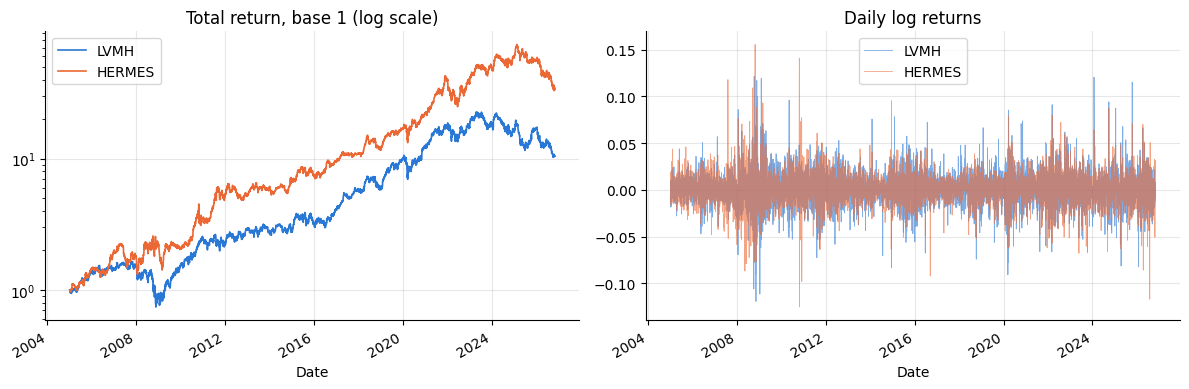

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for a in ASSETS:
    (px[a] / px[a].iloc[0]).plot(ax=ax[0], color=COLORS[a], label=a, logy=True)
    r[a].plot(ax=ax[1], color=COLORS[a], alpha=0.6, lw=0.6, label=a)
ax[0].set_title("Total return, base 1 (log scale)"); ax[1].set_title("Daily log returns")
ax[0].legend(); ax[1].legend(); plt.tight_layout(); plt.show()

## 2. Statistical tests

Every test below has a direct consequence on the model choice. Notation: $r^i_t = \ln(S^i_t / S^i_{t-1})$ with the
adjusted close; $\varepsilon^i_t$ the residuals standardised by a univariate GARCH(1,1) with Student-$t$ innovations.

### 2.1 Marginals

Normality (Jarque-Bera), autocorrelation of returns and of squared returns (Ljung-Box) and conditional
heteroskedasticity (Engle's ARCH-LM test). A rejection of no-ARCH matters for the correlation: with time-varying
volatilities, tests on raw returns over-reject the constancy of the correlation, so the dependence tests are repeated
on GARCH-standardised residuals.

In [4]:
display(ct.marginal_tests(r))
eps, garch_params = ct.garch_standardise(r)
display(garch_params)

,vol (ann.),skew,excess kurt.,Jarque-Bera p,Ljung-Box r (10) p,Ljung-Box r² (10) p,ARCH-LM (5) p
LVMH,0.2831,0.1483,4.889,0,0.01771,1.239e-154,5.741e-63
HERMES,0.273,0.1512,6.284,0,0.2301,4.403e-171,7.273e-89


,omega,alpha,beta,alpha+beta,nu
LVMH,0.03726,0.05009,0.9394,0.9895,5.13
HERMES,0.01887,0.05266,0.9432,0.9959,5.093


*Reading.* Excess kurtosis of 5-6 and strong volatility clustering (squared returns: $p \approx 10^{-150}$; GARCH
persistence $\alpha + \beta \approx 0.99$; Student $\nu \approx 5$). Returns themselves are nearly unpredictable. The
volatility moves a lot through time, so dependence is studied both on $r_t$ and on $\varepsilon_t$.

### 2.2 Correlation and return horizon

For assets traded on different time zones, the correlation of daily returns is biased downwards (non-synchronous
closes, Epps effect) and multi-day returns are used. Correlation of non-overlapping $h$-day returns with the Fisher 95%
interval:

In [5]:
ct.horizon_correlation(px)

,n,rho,95% low,95% high
horizon (days),,,,
1,5588,0.605,0.5881,0.6214
2,2794,0.6185,0.5951,0.6409
5,1117,0.5993,0.5604,0.6356
10,558,0.6087,0.5536,0.6584
20,279,0.5563,0.4695,0.6324
60,93,0.605,0.4577,0.72


*Reading.* The correlation is flat in the horizon (about 0.60 from 1 to 60 days, every interval contains the daily
value): no synchronicity bias, **daily returns can be used**, which gives 5 times more observations than weekly ones.

### 2.3 Is the correlation constant?

**Equality across years.** Under iid normality, $z_k = \operatorname{artanh} \hat\rho_k$ is approximately
$\mathcal N(\operatorname{artanh} \rho, 1/(n_k - 3))$, and under $H_0: \rho_1 = \dots = \rho_K$,
$$Q = \sum_k (n_k - 3)(z_k - \bar z)^2 \sim \chi^2_{K-1}.$$

,Q,df,p-value,pooled rho
raw returns,490.1,21,1.722e-90,0.6317
GARCH residuals,428.6,21,1.109e-77,0.6311


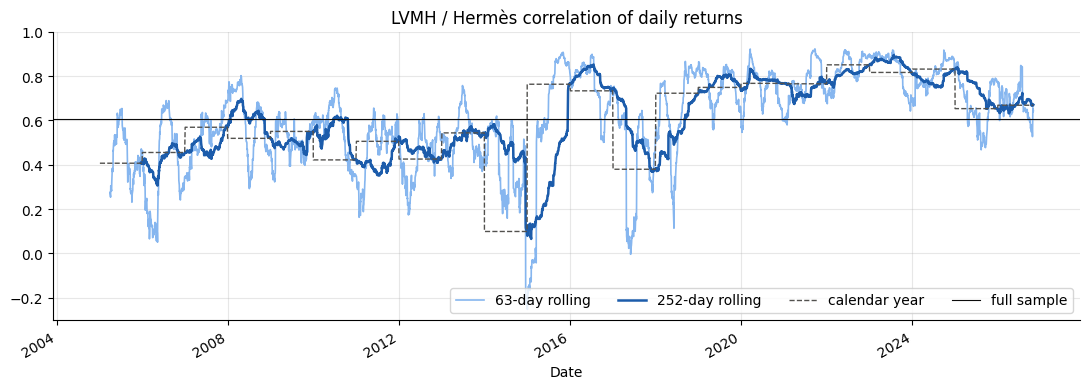

period,2005-12-31,2006-12-31,2007-12-31,2008-12-31,2009-12-31,2010-12-31,2011-12-31,2012-12-31,2013-12-31,2014-12-31,...,2017-12-31,2018-12-31,2019-12-31,2020-12-31,2021-12-31,2022-12-31,2023-12-31,2024-12-31,2025-12-31,2026-12-31
yearly rho,0.4072,0.4557,0.5695,0.5194,0.5507,0.4222,0.506,0.426,0.544,0.09927,...,0.38,0.723,0.7493,0.7676,0.7656,0.8511,0.8168,0.8319,0.6535,0.6688


In [6]:
years_r, test_r = ct.subperiod_equality_test(r)
years_e, test_e = ct.subperiod_equality_test(eps)
display(pd.DataFrame({"raw returns": test_r, "GARCH residuals": test_e}).T)

fig, ax = plt.subplots()
roll = {w: r.LVMH.rolling(w).corr(r.HERMES) for w in (63, 252)}
roll[63].plot(ax=ax, color="#86b6ef", label="63-day rolling")
roll[252].plot(ax=ax, color="#1c5cab", lw=1.8, label="252-day rolling")
yearly = pd.Series(years_r.rho.values, index=pd.to_datetime([f"{p.year}-07-01" for p in years_r.index]))
yearly.reindex(roll[63].index, method="nearest").plot(ax=ax, color="#52514e", ls="--", lw=1, label="calendar year")
ax.axhline(r.corr().iloc[0, 1], color="#0b0b0b", lw=0.8, label="full sample")
ax.set_title("LVMH / Hermès correlation of daily returns"); ax.set_ylim(-0.3, 1); ax.legend(ncol=4, loc="lower right")
plt.tight_layout(); plt.show()
years_r.rho.to_frame("yearly rho").T

**Constancy of the conditional correlation (Engle-Sheppard 2001).** The standardised residuals are whitened with the
constant correlation matrix, $u_t = \bar R^{-1/2} \varepsilon_t$; under a constant conditional correlation the cross
product $Y_t = u^1_t u^2_t$ has no predictability. Regress $Y_t$ on a constant and $s$ lags:
$\hat\delta^\top X^\top X \hat\delta / \hat\sigma^2 \sim \chi^2_{s+1}$.

In [7]:
ct.engle_sheppard_test(eps)

,statistic,df,p-value
lags,,,
1,23.28,2,8.826e-06
5,33.05,6,1.025e-05
10,47.05,11,2.106e-06


*Reading.* Constancy is rejected by both tests, on raw returns and on GARCH residuals ($p < 10^{-5}$ everywhere). The
yearly correlation ranges from 0.10 (2014) to 0.85 (2022), with a clear level shift around 2015: about 0.5 before,
about 0.75 after. A single historical correlation over 20 years would mix two regimes, so **the estimation window or
the weighting of observations is a first-order choice**, not a detail.

### 2.4 Constant, integrated or mean-reverting conditional correlation

Three nested specifications of the conditional correlation of $\varepsilon_t$, fitted by maximum likelihood (correlation
part of the Gaussian likelihood, two-step estimation of Engle 2002):

| model | recursion on $Q_t$, $\rho_t = Q_{12,t} / \sqrt{Q_{11,t} Q_{22,t}}$ | forecast $\mathbb E_t[\rho_{t+h}]$ |
|---|---|---|
| CCC | $Q_t = \bar Q$ | constant |
| EWMA | $Q_t = (1-\lambda)\, \varepsilon_{t-1}\varepsilon_{t-1}^\top + \lambda Q_{t-1}$ | flat at $\rho_t$ (integrated) |
| DCC | $Q_t = (1-a-b)\bar Q + a\, \varepsilon_{t-1}\varepsilon_{t-1}^\top + b\, Q_{t-1}$ | reverts to $\bar\rho$ at speed $(a+b)^h$ |

All three are deterministic given the past: they are candidates for a non-stochastic pricing correlation. The
question for pricing is the forecast column: a 1 to 5 year product needs $\rho$ over the horizon, not tomorrow.

,loglik,k,AIC,BIC,params
model,,,,,
CCC,1293,1,-2584,-2578,{'rho': 0.6086}
EWMA,1485,1,-2968,-2961,{'lambda': 0.9774}
DCC,1515,3,-3023,-3004,"{'a': 0.0305, 'b': 0.961, 'a+b': 0.9915, 'half..."


,H0,H1,LR,df,p-value
0,CCC (constant),DCC,443.1,2,5.971e-97
1,"EWMA (integrated, a+b=1)",DCC,59.81,1,1.044e-14
2,CCC (constant),EWMA,383.3,1,2.36e-85


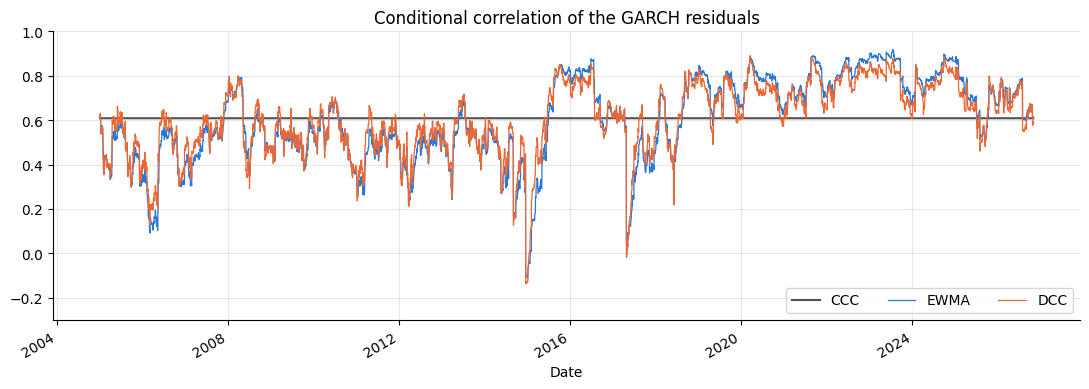

In [8]:
models, lr_tests, cond_rho, cond_params = ct.compare_conditional_models(eps)
display(models); display(lr_tests)

fig, ax = plt.subplots()
for m, c in [("CCC", "#52514e"), ("EWMA", "#2a78d6"), ("DCC", "#eb6834")]:
    cond_rho[m].plot(ax=ax, color=c, label=m, lw=0.9 if m != "CCC" else 1.5)
ax.set_title("Conditional correlation of the GARCH residuals"); ax.set_ylim(-0.3, 1); ax.legend(ncol=3, loc="lower right")
plt.tight_layout(); plt.show()

*Reading.*
- CCC is rejected against both dynamic models (LR of 380-440): the correlation moves.
- DCC beats the integrated EWMA (LR = 60, $p \approx 10^{-14}$): the conditional correlation is **persistent but
  mean-reverting**, $a + b = 0.9915$, half-life about 80 trading days (4 months). The EWMA fitted on the same residuals
  gives $\lambda \approx 0.977$, well above the 0.93-0.94 of RiskMetrics: a daily $\lambda$ of 0.94 is calibrated for
  1-day risk forecasts, not for a correlation that must hold for years.
- Consequence for pricing: with a half-life of 4 months, a correlation observed today mostly reverts to its long-run
  level over the life of a 1 to 3 year product. A flat EWMA forecast overweights the current level.

### 2.5 Mean reversion of the realised correlation

A model-free check of the same question: augmented Dickey-Fuller test on the Fisher transform of the rolling
correlation ($H_0$: unit root) and AR(1) coefficient between consecutive non-overlapping windows.

In [9]:
ct.mean_reversion_table(r)

,mean,std,min,max,ADF p,AR(1) non-overlapping
window (days),,,,,,
63,0.6093,0.2056,-0.252,0.9233,0.0003893,0.5944
126,0.6108,0.1862,-0.08001,0.9015,0.05354,0.6035
252,0.6102,0.1692,0.06559,0.8949,0.1272,0.6979


*Reading.* At the 63-day window, the unit root is rejected ($p < 10^{-3}$) and two consecutive quarters only share an
AR(1) of 0.6: short-term correlation reverts. At 252 days the test loses power (overlapping windows, about 20
independent years) and the persistence is higher (0.7), consistent with a slow-moving long-run level (the 2015 shift)
on top of fast fluctuations. Two time scales, hence two questions for the model: the long-run level $\bar\rho$ (which
window?) and the speed of reversion to it.

### 2.6 Asymmetry and tails

The Gaussian copula implied by a correlation matrix is the dependence used by multi-asset Black-Scholes. Three checks
against it, each statistic compared to its value under a Gaussian with the same correlation:
- **exceedance correlations** (Longin-Solnik 2001): correlation conditional on both returns below $-q$ (down) or above
  $q$ (up) standard deviations; it decreases with $q$ even for a Gaussian, so only the gap matters;
- **tail dependence** $\lambda_L(q) = \mathbb P(U < q, V < q) / q$ on ranks, which goes to 0 for a Gaussian copula;
- **regimes**: rolling 21-day correlation in high / low volatility and down / up markets, against a constant correlation
  simulation with the same volatility path (conditioning on high volatility raises the sample correlation even when the
  true one is constant, Forbes-Rigobon 2002).

In [10]:
exc = pd.concat({"raw returns": ct.exceedance_correlation(r), "GARCH residuals": ct.exceedance_correlation(eps)}, axis=1)
display(exc)
display(pd.concat({"raw returns": ct.tail_dependence(r), "GARCH residuals": ct.tail_dependence(eps)}, axis=1))
display(pd.concat([ct.regime_correlation(r), ct.regime_correlation_benchmark(r)], axis=1))

raw returns                       GARCH residuals           \
                      n rho data rho gaussian               n rho data   
q (sd) side                                                              
0      down        1996   0.5113        0.362            1994   0.5003   
       up          2029   0.5117       0.3607            2029   0.4418   
0.5    down         862   0.4626       0.3043             917   0.4531   
       up           819   0.5175       0.3046             898   0.4183   
1      down         349   0.3323        0.252             364   0.3666   
       up           288   0.4459       0.2544             325   0.4214   
1.5    down         135    0.276       0.2026             143   0.2409   
       up           119   0.3618       0.2157             109   0.4719   

                          
            rho gaussian  
q (sd) side               
0      down       0.3652  
       up         0.3642  
0.5    down       0.3075  
       up         0.3074  
1      down       0.2549  
       up          0.257  
1.5    down       0.2062  
       up         0.2182

raw returns                                      GARCH residuals  \
      lower data upper data gaussian joint obs. lower      lower data   
q                                                                       
0.1         0.51     0.4563   0.3937              285          0.4957   
0.05      0.4116     0.3937   0.3142              115          0.4331   
0.01      0.1969     0.4295   0.1911               11          0.3042   

                                           
     upper data gaussian joint obs. lower  
q                                          
0.1      0.4116   0.3963              277  
0.05     0.3579   0.3168              121  
0.01     0.2684   0.1936               17

,mean rolling correlation,constant-corr. benchmark
high vol (top 20%),0.6609,0.6241
low vol (bottom 20%),0.4526,0.5453
down market (21d basket < 0),0.6385,0.5862
up market (21d basket > 0),0.5825,0.5904
all,0.6055,0.5883


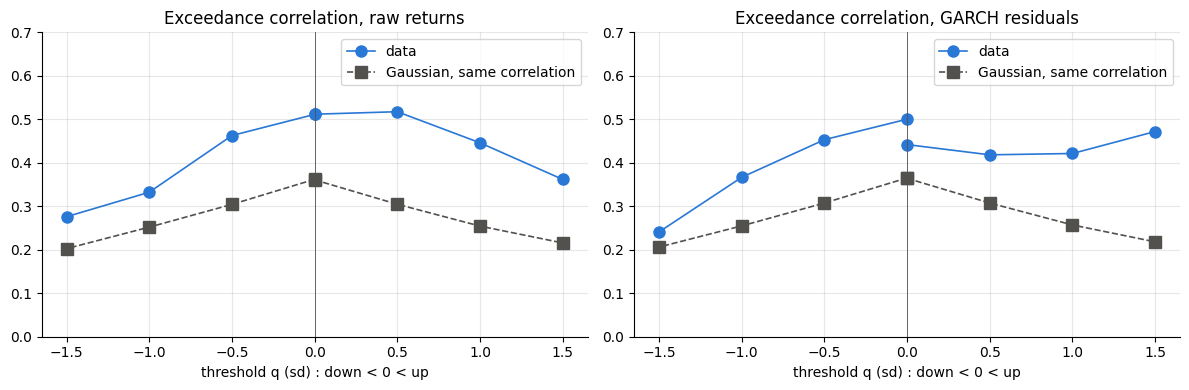

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for k, (name, df) in enumerate([("raw returns", exc["raw returns"]), ("GARCH residuals", exc["GARCH residuals"])]):
    for side, sign in [("down", -1), ("up", 1)]:
        d = df.xs(side, level=1)
        x = sign * d.index.values
        ax[k].plot(x, d["rho data"], "o-", color="#2a78d6", ms=8, label="data" if side == "up" else None)
        ax[k].plot(x, d["rho gaussian"], "s--", color="#52514e", ms=8,
                   label="Gaussian, same correlation" if side == "up" else None)
    ax[k].axvline(0, color="#52514e", lw=0.6)
    ax[k].set_title(f"Exceedance correlation, {name}"); ax[k].set_xlabel("threshold q (sd) : down < 0 < up")
    ax[k].set_ylim(0, 0.7); ax[k].legend()
plt.tight_layout(); plt.show()

*Reading.*
- Exceedance correlations are above the Gaussian benchmark at every threshold, on both sides: part of it is the
  time variation of the correlation (a mixture of Gaussians with different $\rho$ has fatter joint tails). On GARCH
  residuals the up side stays high at 1.5 sd (0.47 against 0.22) while the down side falls back to the Gaussian
  level: no sign of a "correlation goes to 1 in crashes" effect for this pair; the strong co-movements are joint
  rallies (sector news, China).
- Empirical tail dependence is above the Gaussian at 10% and 5% on both tails; at 1% the estimates rest on 11 to 17
  joint observations and are not conclusive.
- Correlation is higher in high-volatility regimes (0.66 against 0.45 in low volatility); the constant-correlation
  benchmark explains about 40% of the gap (0.62 against 0.55). Down markets show a slightly higher correlation
  than up markets (0.64 against 0.58, benchmark 0.59 on both).

### 2.7 Synthesis

| test | result | consequence for the model |
|---|---|---|
| marginals | fat tails, strong volatility clustering | test dependence on GARCH residuals; volatility choice matters as much as correlation |
| horizon | flat correlation from 1 to 60 days | daily returns, no synchronicity correction |
| constancy | rejected (Fisher z, Engle-Sheppard); shift around 2015 | window / weighting is first-order; a 20-year historical average is biased |
| CCC / EWMA / DCC | DCC preferred; $a+b = 0.9915$, half-life about 4 months; EWMA $\lambda \approx 0.977$ | a mean-reverting forecast over the product horizon is supported against a flat EWMA forecast |
| mean reversion | short-term correlation reverts; slow long-run level | two scales: long-run level and reversion speed |
| tails and regimes | joint tails fatter than Gaussian, mostly upside; higher correlation in high volatility | Gaussian dependence understates joint extremes; correlation linked to volatility level |

These results set the list of candidate models to build and compare in the next sections.

## 3. Candidate models

Six non-stochastic models, chosen from the results of section 2, are implemented in `correlation_models.py` with a
common interface: `fit(r)` on the daily returns known at the pricing date $t_0$, then
$$\rho(H) = \frac1H \sum_{h=1}^{H} \mathbb E_{t_0}[\rho_{t_0+h}],$$
the average forecast correlation over the next $H$ trading days. In a multi-asset Black-Scholes model with constant
volatilities, the terminal log-returns are Gaussian with covariance $\sigma_1\sigma_2 \int_0^T \rho(t)\,dt$, so for a
European payoff only this average matters: $\rho(H)$ is the input of the pricer. The daily path
$\mathbb E_{t_0}[\rho_{t_0+h}]$ (`forecast_path`) is kept for path-dependent products.

All models are fitted here on the whole history, at the pricing date $t_0$ = last date of the sample; the out-of-sample
comparison comes next. Maturities: 3 months to 3 years, in trading days.

In [12]:
H_GRID = {"3m": 63, "6m": 126, "1y": 252, "2y": 504, "3y": 756}
t0 = r.index[-1]
print("pricing date :", t0.date())

pricing date : 2026-10-30


### 3.1 Historical correlation

$\hat\rho$ over a window: the whole sample, the last year, the last three years, since the 2015 shift, or a window equal
to the maturity of the product. The forecast is flat; only the window changes, and section 2.3 showed that it is a
first-order choice.

In [13]:
historical = [cm.HistoricalCorrelation(), cm.HistoricalCorrelation(window=252), cm.HistoricalCorrelation(window=756),
              cm.HistoricalCorrelation(start="2015"), cm.HistoricalCorrelation(match_maturity=True)]
for m in historical:
    m.fit(r)
pd.DataFrame([m.term_structure(H_GRID.values()).set_axis(H_GRID.keys()) for m in historical])

,3m,6m,1y,2y,3y
"historical, full sample",0.605,0.605,0.605,0.605,0.605
historical 252d,0.6706,0.6706,0.6706,0.6706,0.6706
historical 756d,0.6998,0.6998,0.6998,0.6998,0.6998
historical since 2015,0.7429,0.7429,0.7429,0.7429,0.7429
"historical, window = maturity",0.6446,0.6604,0.6706,0.66,0.6998


*Reading.* From 0.61 (whole sample, which mixes the two regimes) to 0.74 (since 2015): a spread of 0.14 of correlation
from the window alone. The window equal to the maturity gives 0.65 to 0.70 depending on the horizon.

### 3.2 EWMA

$$Q_t = (1-\lambda)\, x_{t-1} x_{t-1}^\top + \lambda\, Q_{t-1}, \qquad \rho_t = \frac{Q_{12,t}}{\sqrt{Q_{11,t}Q_{22,t}}},$$
on raw returns ($x = r$, RiskMetrics, zero mean, full Gaussian likelihood) or on GARCH residuals ($x = \varepsilon$,
correlation part of the likelihood). Two criteria for $\lambda$:
- **likelihood**: best one-day-ahead density;
- **forecast**: minimises $\sum_t \big(\rho_t - \hat\rho^{\text{real}}_{[t,\, t+H-1]}\big)^2$, the error against the
  correlation realised over the next $H = 252$ days, which is what a one-year product needs.

The forecast is flat: $\rho(H) = \rho_{t_0+1}$ for every maturity.

In [14]:
ewma = [cm.EWMACorrelation(on="returns"), cm.EWMACorrelation(on="residuals"),
        cm.EWMACorrelation(on="returns", criterion="forecast"), cm.EWMACorrelation(on="residuals", criterion="forecast")]
for m in ewma:
    m.fit(r)
pd.DataFrame({m.name: m.params for m in ewma}).T

,lambda,half-life (days),rho_next
"EWMA returns, likelihood",0.9705,23.13,0.613
"EWMA residuals, likelihood",0.9777,30.71,0.6128
"EWMA returns, forecast",0.9982,391.4,0.7088
"EWMA residuals, forecast",0.9981,360.2,0.7241


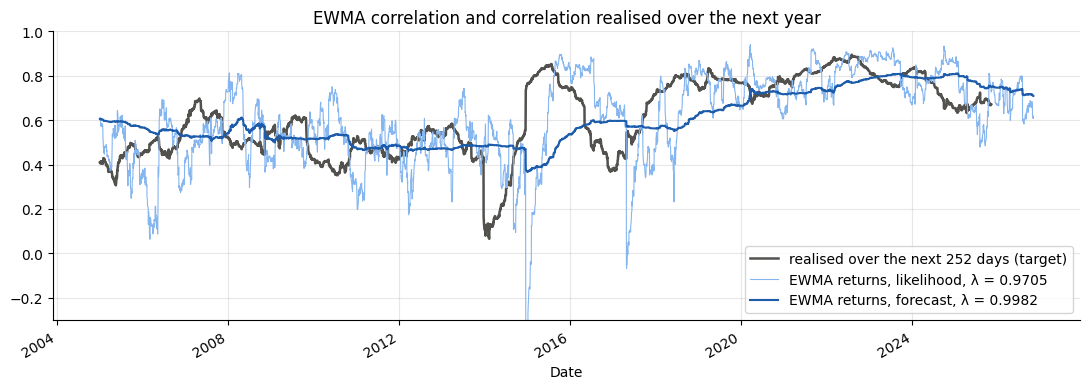

In [15]:
fig, ax = plt.subplots()
cm.realised_forward_correlation(r, 252).plot(ax=ax, color="#52514e", lw=1.8, label="realised over the next 252 days (target)")
ewma[0].rho_path.plot(ax=ax, color="#86b6ef", lw=0.8, label=f"EWMA returns, likelihood, λ = {ewma[0].lam:.4f}")
ewma[2].rho_path.plot(ax=ax, color="#1c5cab", lw=1.5, label=f"EWMA returns, forecast, λ = {ewma[2].lam:.4f}")
ax.set_title("EWMA correlation and correlation realised over the next year"); ax.set_ylim(-0.3, 1)
ax.legend(loc="lower right"); plt.tight_layout(); plt.show()

*Reading.* The criterion changes $\lambda$ by an order of magnitude in memory: the likelihood picks $\lambda \approx 0.97$
(half-life of 23 to 31 days), the one-year forecast error picks $\lambda \approx 0.998$ (half-life of about one year).
The one-day-optimal EWMA tracks noise that does not persist over a year; the RiskMetrics value of 0.94 is even shorter.
For pricing, $\lambda$ has to be chosen for the horizon of the product, and it then gives 0.71 to 0.72 today instead
of 0.61.

### 3.3 DCC forecast

DCC(1,1) on GARCH residuals (section 2.4), with the mean-reverting forecast of Engle and Sheppard:
$$\mathbb E_{t_0}[\rho_{t_0+h}] \approx \bar\rho + (a+b)^{h-1}(\rho_{t_0+1} - \bar\rho), \qquad
\rho(H) = \bar\rho + w(H)\,(\rho_{t_0+1} - \bar\rho), \quad w(H) = \frac{1-(a+b)^H}{H(1-a-b)}.$$

In [16]:
dcc = cm.DCCCorrelation().fit(r)
display(pd.Series(dcc.params, name="DCC").to_frame().T)
print("w(H) :", {k: round(float(cm.BlendCorrelation.weight(H, dcc.a + dcc.b)), 3) for k, H in H_GRID.items()})

,a,b,a+b,half-life (days),rho_bar,rho_next
DCC,0.03052,0.961,0.9915,81.65,0.6086,0.5908


w(H) : {'3m': 0.778, '6m': 0.617, '1y': 0.414, '2y': 0.231, '3y': 0.156}


*Reading.* Today's conditional correlation (0.59) is close to the long-run level, so the DCC term structure is almost
flat around 0.60. The weakness is the target: $\bar\rho = 0.61$ is the average of the **whole** sample, which mixes the
regimes before and after 2015 (0.47 and 0.74). The DCC reverts to a level that has not been observed for ten years.

### 3.4 Blend of a short and a long window

The same structure as the DCC forecast, with model-free anchors:
$$\mathbb E_{t_0}[\rho_{t_0+h}] = \rho_{\text{long}} + \varphi^{h-1}(\rho_{\text{short}} - \rho_{\text{long}}),$$
with $\rho_{\text{short}}$ and $\rho_{\text{long}}$ the historical correlations over the last 63 and 756 days, and
$\varphi = 0.5^{1/\text{half-life}}$ fitted by least squares on the correlations realised over 3, 6, 12 and 24 months.
The long anchor (3 years) follows the 2015 shift, unlike the DCC target.

In [17]:
blend = cm.BlendCorrelation().fit(r)
pd.Series(blend.params, name=blend.name).to_frame().T

,rho_short,rho_long,half-life (days),w(252)
blend 63d / 756d,0.6446,0.6998,14.99,0.08783


*Reading.* The fitted half-life is short (15 days): beyond a few weeks, the last quarter carries little information
that the last three years do not already have. At one year the weight of the short window is 9%, so the blend is
essentially the three-year historical correlation (0.69 to 0.70).

### 3.5 Regime switching

Two regimes $s_t \in \{\text{low}, \text{high}\}$ following a Markov chain with transition matrix $P$; given $s_t = k$,
the GARCH residuals are bivariate normal with correlation $\rho_k$ (Hamilton 1989). Maximum likelihood with the Hamilton
filter; the forecast uses the filtered probabilities $\pi_{t_0}$ at the pricing date:
$$\mathbb E_{t_0}[\rho_{t_0+h}] = \pi_{t_0}^\top P^h \rho, \qquad \rho = (\rho_{\text{low}}, \rho_{\text{high}})^\top.$$

,rho_low,rho_high,"p_low,low","p_high,high",duration low (days),duration high (days),P(high) today
regime switching,0.3345,0.829,0.9299,0.9526,14.26,21.09,0.4809


correlation log-likelihood : regime switching 1644.2 (4 parameters), DCC 1514.7 (3), CCC 1293.2 (1)


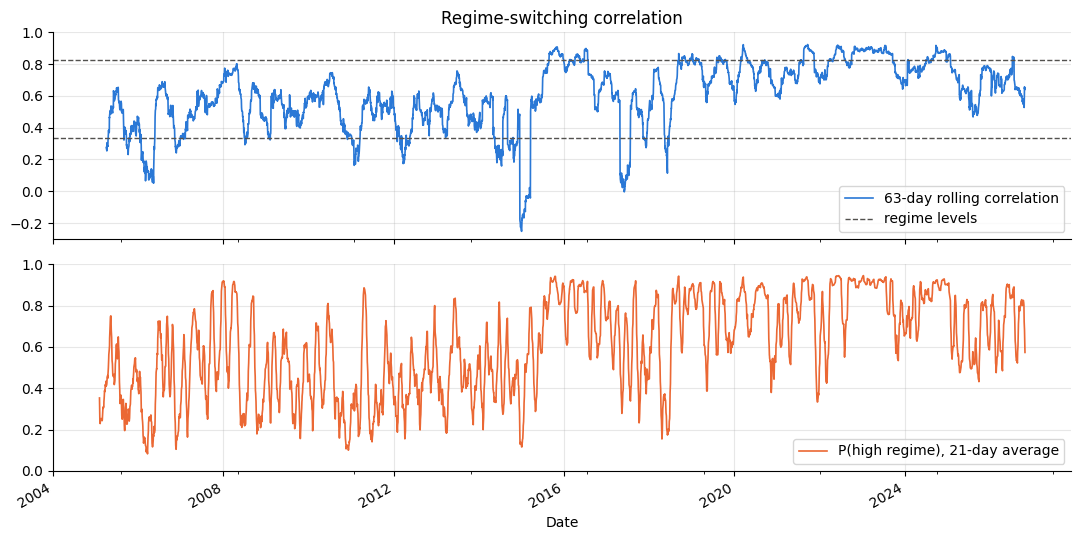

In [18]:
regime = cm.RegimeSwitchingCorrelation().fit(r)
display(pd.Series(regime.params, name="regime switching").to_frame().T)
print(f"correlation log-likelihood : regime switching {regime.loglik_correlation:.1f} (4 parameters), "
      f"DCC {models.loc['DCC', 'loglik']:.1f} (3), CCC {models.loc['CCC', 'loglik']:.1f} (1)")

fig, ax = plt.subplots(2, 1, figsize=(11, 5.5), sharex=True)
r.LVMH.rolling(63).corr(r.HERMES).plot(ax=ax[0], color="#2a78d6", label="63-day rolling correlation")
ax[0].axhline(regime.rho[0], color="#52514e", ls="--", lw=1, label="regime levels")
ax[0].axhline(regime.rho[1], color="#52514e", ls="--", lw=1)
ax[0].set_ylim(-0.3, 1); ax[0].legend(loc="lower right"); ax[0].set_title("Regime-switching correlation")
regime.probabilities["high"].rolling(21).mean().plot(ax=ax[1], color="#eb6834", label="P(high regime), 21-day average")
ax[1].set_ylim(0, 1); ax[1].legend(loc="lower right")
plt.tight_layout(); plt.show()

*Reading.* The likelihood separates a low regime (about 0.33) and a high regime (about 0.83), each lasting two to four
weeks on average. In likelihood it beats the DCC by about 130 points with one more parameter: a correlation that
jumps between two levels fits the residuals better than a smooth GARCH-type recursion. The model captures the fast
fluctuations, not the 2015 shift: the share of time in the high regime
rises after 2015, but the regimes switch too often to represent a permanent level change. The forecast reverts to the
stationary mix of the two levels (about 0.63). A model with a third, persistent regime, or with regime-dependent
volatilities, would be needed to separate the two time scales.

### 3.6 Student-t copula

The previous models give a correlation for a Gaussian dependence. The Student-$t$ copula keeps an elliptical dependence
with a correlation $\rho$ but adds $\nu$ degrees of freedom, hence a tail dependence
$$\lambda = 2\, t_{\nu+1}\!\left(-\sqrt{\frac{(\nu+1)(1-\rho)}{1+\rho}}\right),$$
equal on both tails, which is 0 for the Gaussian copula. Fitted on the ranks of the GARCH residuals:
$\rho = \sin(\pi\tau/2)$ from Kendall's $\tau$ (valid for every elliptical copula, robust to the fat tails), then $\nu$ by
maximum likelihood given $\rho$.

In [19]:
tcop = cm.StudentTCopula().fit(r)
display(pd.Series(tcop.params, name=tcop.name).to_frame().T)
emp = ct.tail_dependence(eps, quantiles=(0.10, 0.05, 0.01))
U = np.random.default_rng(0).standard_normal((2_000_000, 2))
sim = pd.DataFrame(U @ np.linalg.cholesky([[1, tcop.rho], [tcop.rho, 1]]).T
                   / np.sqrt(np.random.default_rng(1).chisquare(tcop.nu, (2_000_000, 1)) / tcop.nu))
emp["t copula"] = ct.tail_dependence(sim, quantiles=(0.10, 0.05, 0.01))["lower data"].values
emp[["lower data", "upper data", "gaussian", "t copula"]]

,tau,rho,nu,tail dependence,LR vs gaussian
Student-t copula,0.4428,0.6408,5.084,0.2918,267.1


,lower data,upper data,gaussian,t copula
q,,,,
0.1,0.4957,0.4116,0.3963,0.4618
0.05,0.4331,0.3579,0.3168,0.4122
0.01,0.3042,0.2684,0.1936,0.3496


*Reading.* $\nu \approx 5$ and a likelihood ratio of about 270 against the Gaussian copula: the Gaussian dependence is
clearly rejected. The fitted copula reproduces the empirical tail dependence of the residuals at 10% and 5% far better
than the Gaussian, with an asymptotic coefficient of 0.29. Its limit is symmetry: it puts the same dependence on both
tails, while section 2.6 found the excess mostly on the upside. The correlation from Kendall's $\tau$ (0.64) is a
little above the Pearson value (0.61), which outliers pull down.

### 3.7 Pricing correlations at the pricing date

In [20]:
all_models = historical + ewma + [dcc, blend, regime, tcop]
term = pd.DataFrame([m.term_structure(H_GRID.values()).set_axis(H_GRID.keys()) for m in all_models])
display(term.style.format("{:.3f}").background_gradient(cmap="Blues", axis=None, vmin=0.55, vmax=0.8))
print(f"1-year pricing correlation : min {term['1y'].min():.3f}, max {term['1y'].max():.3f}, "
      f"spread {term['1y'].max() - term['1y'].min():.3f}")

,3m,6m,1y,2y,3y
"historical, full sample",0.605,0.605,0.605,0.605,0.605
historical 252d,0.671,0.671,0.671,0.671,0.671
historical 756d,0.700,0.700,0.700,0.700,0.700
historical since 2015,0.743,0.743,0.743,0.743,0.743
"historical, window = maturity",0.645,0.660,0.671,0.660,0.700
"EWMA returns, likelihood",0.613,0.613,0.613,0.613,0.613
"EWMA residuals, likelihood",0.613,0.613,0.613,0.613,0.613
"EWMA returns, forecast",0.709,0.709,0.709,0.709,0.709
"EWMA residuals, forecast",0.724,0.724,0.724,0.724,0.724
DCC,0.595,0.598,0.601,0.604,0.606


1-year pricing correlation : min 0.601, max 0.743, spread 0.142


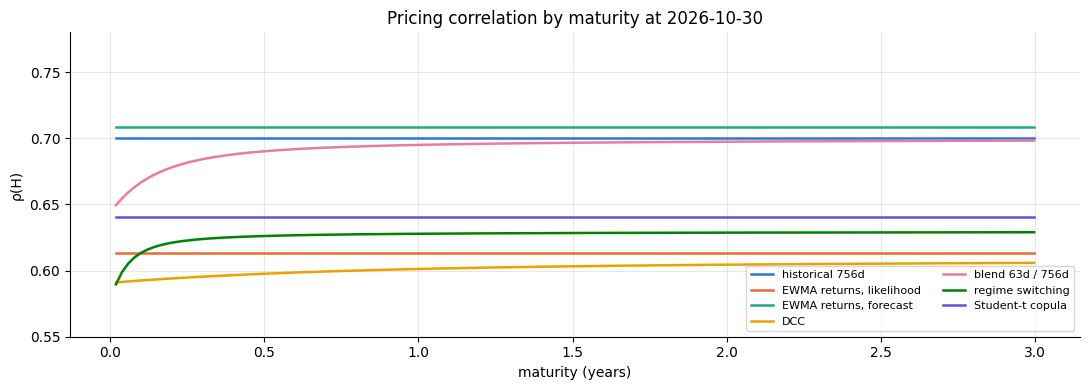

In [21]:
shown = [(historical[2], "#2a78d6"), (ewma[0], "#eb6834"), (ewma[2], "#1baf7a"), (dcc, "#eda100"),
         (blend, "#e87ba4"), (regime, "#008300"), (tcop, "#6250d6")]
Hs = np.arange(5, 757, 5)
fig, ax = plt.subplots()
for m, c in shown:
    ax.plot(Hs / 252, [m.pricing_correlation(H) for H in Hs], color=c, lw=1.8, label=m.name)
ax.set_xlabel("maturity (years)"); ax.set_ylabel("ρ(H)"); ax.set_ylim(0.55, 0.78)
ax.set_title(f"Pricing correlation by maturity at {t0.date()}")
ax.legend(ncol=2, fontsize=8, loc="lower right"); plt.tight_layout(); plt.show()

*Reading.* At the same date and with the same data, the six families give one-year pricing correlations between about
0.60 and 0.74. The models split into two groups:
- those anchored on the **whole sample** (full historical, DCC, EWMA fitted by likelihood, regime switching):
  0.60 to 0.63;
- those anchored on the **recent years** (three-year or post-2015 historical, blend, EWMA fitted on the one-year
  forecast error): 0.69 to 0.74.

The spread comes less from the dynamics than from **which long-run level** the model trusts, which is the 2015 question
of section 2.3. Only an out-of-sample comparison can decide between the two groups. It is the next step, together with
the impact of this spread on the prices of worst-of and best-of options.

## 4. Out-of-sample comparison

**Protocol.** Every 21 trading days from January 2008, each model is refitted on the returns known at the close of
$t$ (expanding window: nothing after $t$ is used, including for the choice of $\lambda$, of the blend half-life or of
the regime parameters) and gives its pricing correlation $\rho(H)$ for $H$ = 3, 6, 12 and 24 months. The target is the
correlation of the daily returns realised over $[t+1,\, t+H]$, the correlation a delta-hedged position would actually
have experienced. The historical correlation since 2015 is left out: its start date is chosen with hindsight.

**Criteria.** Bias (forecast minus realised: a positive bias overstates the correlation, which underprices worst-of puts
and overprices worst-of calls), MAE and RMSE. Each model is compared with the best one at the same horizon by a
Diebold-Mariano test of equal squared error; consecutive targets overlap over $\lceil H/21 \rceil - 1$ dates, so the
variance of the loss differential is Newey-West with that many lags. With overlapping windows the number of independent
observations is small (about 4 at 12 months on the test sample), so the tests have little power: a large $p$-value
means "not distinguishable", not "equivalent".

**Two evaluation samples.**
- the **test sample** of the 80 / 20 split (last 20% of the data, from mid-2022), as planned in section 2;
- the **long sample**, January 2008 onwards, which contains the 2015 shift. On 2022-2026 the correlation stayed high,
  which favours the models anchored on recent years; the long sample tests whether they adapt when the level moves.

The backtest takes about 10 minutes (the regime-switching fit dominates): it is cached in `correlation_backtest.csv`.

In [22]:
BACKTEST = "correlation_backtest.csv"
RECOMPUTE = False
if RECOMPUTE or not os.path.exists(BACKTEST):
    bt = cm.backtest(r, cm.backtest_factories(), start="2008-01-01", verbose=True)
    bt.to_csv(BACKTEST, index=False, float_format="%.6f")
bt = pd.read_csv(BACKTEST, parse_dates=["date"])

split = r.index[int(0.8 * len(r))]
LABEL = {v: k for k, v in H_GRID.items()}
ORDER = list(cm.backtest_factories())

def by_horizon(table, column):
    out = table[column].unstack("H").rename(columns=LABEL)
    return out.reindex(ORDER)

print(f"{bt.date.nunique()} refit dates, {bt.date.min().date()} -> {bt.date.max().date()} ; test sample from {split.date()}")

230 refit dates, 2008-01-02 -> 2026-10-19 ; test sample from 2022-06-20


### 4.1 Test sample (80 / 20 split)

In [23]:
test_table, test_errors = cm.evaluate(bt, r, start=split)
display(by_horizon(test_table, "n").iloc[:1].rename(index={ORDER[0]: "number of forecasts"}))
display(by_horizon(test_table, "RMSE").style.format("{:.3f}").highlight_min(axis=0, props="font-weight: bold")
        .set_caption("RMSE"))
display(by_horizon(test_table, "bias").style.format("{:+.3f}").set_caption("Bias (forecast - realised)"))
display(by_horizon(test_table, "DM p-value").style.format("{:.2f}", na_rep="best")
        .set_caption("Diebold-Mariano p-value against the best model"))

H,3m,6m,1y,2y
model,,,,
number of forecasts,50,47,41,29


H,3m,6m,1y,2y
model,,,,
"historical, full sample",0.208,0.200,0.187,0.183
historical 252d,0.110,0.099,0.090,0.083
historical 756d,0.113,0.100,0.095,0.081
"historical, window = maturity",0.116,0.102,0.090,0.090
"EWMA returns, likelihood",0.112,0.102,0.111,0.099
"EWMA residuals, likelihood",0.116,0.105,0.113,0.099
"EWMA returns, forecast",0.108,0.093,0.083,0.068
"EWMA residuals, forecast",0.115,0.100,0.090,0.072
DCC,0.130,0.134,0.144,0.154


H,3m,6m,1y,2y
model,,,,
"historical, full sample",-0.171,-0.174,-0.168,-0.173
historical 252d,+0.019,+0.024,+0.052,+0.067
historical 756d,+0.032,+0.034,+0.049,+0.050
"historical, window = maturity",+0.013,+0.020,+0.052,+0.066
"EWMA returns, likelihood",+0.012,+0.012,+0.032,+0.069
"EWMA residuals, likelihood",+0.018,+0.019,+0.037,+0.068
"EWMA returns, forecast",+0.016,+0.017,+0.030,+0.033
"EWMA residuals, forecast",+0.016,+0.016,+0.028,+0.027
DCC,-0.062,-0.091,-0.113,-0.141


H,3m,6m,1y,2y
model,,,,
"historical, full sample",0.00,0.01,0.04,0.01
historical 252d,0.39,0.53,0.43,0.10
historical 756d,0.18,0.29,0.20,0.12
"historical, window = maturity",0.43,0.46,0.43,0.03
"EWMA returns, likelihood",0.55,0.55,0.02,0.00
"EWMA residuals, likelihood",0.30,0.40,0.01,0.00
"EWMA returns, forecast",0.47,best,best,best
"EWMA residuals, forecast",0.11,0.01,0.04,0.14
DCC,0.12,0.12,0.14,0.04


*Reading.* On the test sample (mid-2022 onwards), the models anchored on recent years win.
- The EWMA with $\lambda$ fitted on the one-year forecast error has the lowest RMSE from 6 months on (0.083 at one year,
  0.068 at two years) and the blend at 3 months (0.104). The one- and three-year historical correlations are close
  (0.090 and 0.095 at one year) and not distinguishable from the best (Diebold-Mariano $p$ = 0.43 and 0.20).
- The models whose long-run level is the full-sample average carry a large negative bias, $-0.11$ to $-0.17$: full
  historical correlation (RMSE 0.19 at one year), regime switching (0.17), Student-$t$ copula (0.16) and DCC (0.14),
  whose target of 0.61 is too low after 2015.
- The EWMA fitted by likelihood is fine at 3 and 6 months but degrades at one and two years (0.111 and 0.099,
  $p$ = 0.02 and 0.002): a memory of one month is too short for long maturities.
- The recent-anchored models overestimate slightly (+0.03 to +0.05 at one year): the correlation fell from 0.83 in
  2024 to 0.65 in 2025.

### 4.2 Long sample, 2008-2026

In [24]:
long_table, long_errors = cm.evaluate(bt, r)
display(by_horizon(long_table, "n").iloc[:1].rename(index={ORDER[0]: "number of forecasts"}))
display(by_horizon(long_table, "RMSE").style.format("{:.3f}").highlight_min(axis=0, props="font-weight: bold")
        .set_caption("RMSE"))
display(by_horizon(long_table, "bias").style.format("{:+.3f}").set_caption("Bias (forecast - realised)"))
display(by_horizon(long_table, "DM p-value").style.format("{:.2f}", na_rep="best")
        .set_caption("Diebold-Mariano p-value against the best model"))

H,3m,6m,1y,2y
model,,,,
number of forecasts,227,224,218,206


H,3m,6m,1y,2y
model,,,,
"historical, full sample",0.216,0.202,0.190,0.179
historical 252d,0.196,0.190,0.193,0.173
historical 756d,0.174,0.155,0.138,0.109
"historical, window = maturity",0.203,0.188,0.193,0.129
"EWMA returns, likelihood",0.198,0.186,0.196,0.199
"EWMA residuals, likelihood",0.189,0.173,0.179,0.179
"EWMA returns, forecast",0.182,0.164,0.151,0.137
"EWMA residuals, forecast",0.186,0.169,0.157,0.145
DCC,0.181,0.172,0.172,0.170


H,3m,6m,1y,2y
model,,,,
"historical, full sample",-0.105,-0.105,-0.103,-0.114
historical 252d,-0.006,-0.005,-0.002,-0.017
historical 756d,-0.013,-0.012,-0.012,-0.030
"historical, window = maturity",+0.001,-0.000,-0.002,-0.023
"EWMA returns, likelihood",+0.006,+0.006,+0.008,-0.002
"EWMA residuals, likelihood",+0.002,+0.002,+0.003,-0.008
"EWMA returns, forecast",-0.041,-0.042,-0.042,-0.060
"EWMA residuals, forecast",-0.052,-0.052,-0.054,-0.072
DCC,-0.057,-0.073,-0.087,-0.108


H,3m,6m,1y,2y
model,,,,
"historical, full sample",0.00,0.00,0.02,0.04
historical 252d,0.05,0.02,0.02,0.03
historical 756d,best,0.39,best,best
"historical, window = maturity",0.11,0.10,0.02,0.03
"EWMA returns, likelihood",0.19,0.11,0.01,0.00
"EWMA residuals, likelihood",0.23,0.13,0.01,0.00
"EWMA returns, forecast",0.22,0.26,0.38,0.22
"EWMA residuals, forecast",0.06,0.10,0.20,0.14
DCC,0.31,0.08,0.07,0.05


*Reading.* Over 2008-2026 the three-year historical correlation and the blend (whose three-year anchor dominates beyond
a few weeks) have the lowest RMSE at every horizon (0.138 at one year, 0.109 and 0.110 at two years), with almost no
bias ($-0.01$ at one year). The EWMA fitted on the forecast error comes next (0.151 at one year, not distinguishable,
$p$ = 0.38) but is biased downwards ($-0.04$): its $\lambda$ is fitted on an expanding sample and a one-year memory lags
the 2015 rise. The full-sample correlation and the short memories (one-year window, EWMA by likelihood) are
significantly worse at one year ($p \le 0.03$). DCC, regime switching and Student-$t$ copula sit in between (RMSE about
0.17 at one year) with a bias of $-0.075$ to $-0.09$.

### 4.3 Before and after the 2015 shift

One-year RMSE on the forecasts made before 2014 (targets ending before the shift) and from 2016 (after it).

In [25]:
periods = {"2008-2013": ("2008-01-01", "2013-12-31"), "2016-2026": ("2016-01-01", None), "test sample": (split, None)}
rmse_1y = pd.DataFrame({k: cm.evaluate(bt[bt.H == 252], r, start=a, end=b)[0].loc[252].RMSE for k, (a, b) in periods.items()})
rmse_1y["long sample"] = long_table.loc[252].RMSE
rmse_1y.reindex(ORDER).style.format("{:.3f}").highlight_min(axis=0, props="font-weight: bold")

,2008-2013,2016-2026,test sample,long sample
model,,,,
"historical, full sample",0.080,0.213,0.187,0.190
historical 252d,0.124,0.148,0.090,0.193
historical 756d,0.090,0.097,0.095,0.138
"historical, window = maturity",0.124,0.148,0.090,0.193
"EWMA returns, likelihood",0.172,0.151,0.111,0.196
"EWMA residuals, likelihood",0.152,0.152,0.113,0.179
"EWMA returns, forecast",0.082,0.143,0.083,0.151
"EWMA residuals, forecast",0.079,0.155,0.090,0.157
DCC,0.080,0.185,0.144,0.172


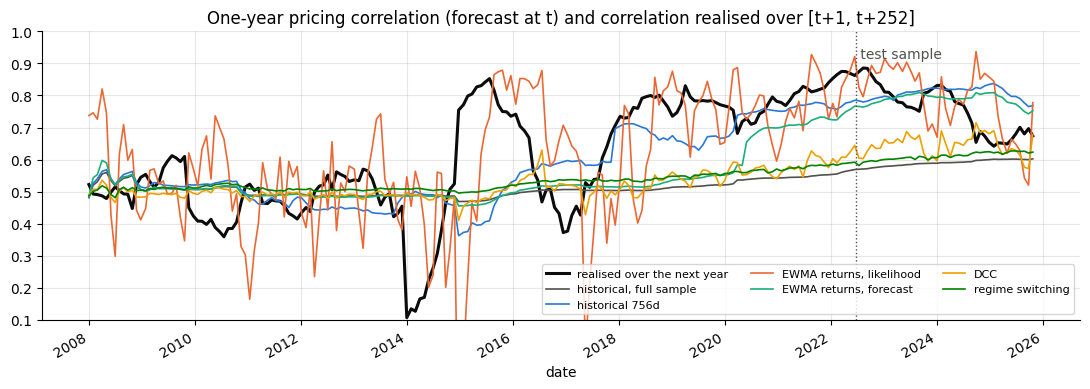

In [26]:
shown = [("historical, full sample", "#52514e"), ("historical 756d", "#2a78d6"), ("EWMA returns, likelihood", "#eb6834"),
         ("EWMA returns, forecast", "#1baf7a"), ("DCC", "#eda100"), ("regime switching", "#008300")]
f1 = long_errors[long_errors.H == 252].pivot(index="date", columns="model", values="forecast")
real = long_errors[long_errors.H == 252].groupby("date").realised.first()
fig, ax = plt.subplots()
real.plot(ax=ax, color="#0b0b0b", lw=2.2, label="realised over the next year")
for name, c in shown:
    f1[name].plot(ax=ax, color=c, lw=1.2, label=name)
ax.axvline(split, color="#52514e", ls=":", lw=1); ax.text(split, 0.95, " test sample", color="#52514e", va="top")
ax.set_title("One-year pricing correlation (forecast at t) and correlation realised over [t+1, t+252]")
ax.set_ylim(0.1, 1); ax.legend(ncol=3, fontsize=8, loc="lower right"); plt.tight_layout(); plt.show()

*Reading.* The ranking depends on the period.
- **Before the shift** (2008-2013, a stable level around 0.5), every long-memory model does about as well: full-sample
  historical correlation, DCC, EWMA by forecast error and regime switching are all at 0.079 to 0.082 at one year. The
  three-year window and the blend are slightly behind (0.090 and 0.094): in a stable regime a shorter window is only
  noisier. The short memories are clearly worse (one-year window 0.124, EWMA by likelihood 0.17).
- **After the shift** (2016-2026), the models whose long-run level is the full-sample average stay biased for years:
  $-0.15$ for the DCC and regime switching at one year, $-0.18$ for the full-sample correlation, RMSE 0.18 to 0.21,
  against 0.095 to 0.097 for the three-year window and the blend.

The figure shows the mechanism: after 2015 the DCC and regime-switching forecasts only move up as fast as the
full-sample mean, while the three-year window catches the new level within three years. What separates the models
is not their short-term dynamics but **how fast their long-run anchor forgets a past regime**.

### 4.4 Synthesis

1. **The long-run anchor is the main choice.** A three-year rolling window (alone or in the blend) is the most robust
   model: best after the shift, best over 2008-2026 at every horizon with no bias, and within 0.015 of the best
   before the shift. Anchoring on the whole history (DCC, regime switching, copula, full historical correlation) works
   in a stable regime and is biased by about $-0.15$ for years after a level shift.
2. **The memory has to match the maturity.** A $\lambda$ chosen for the one-day likelihood (and a fortiori the
   RiskMetrics 0.94) is significantly worse at one and two years; a $\lambda$ chosen on the one-year forecast error is
   competitive but adapts slowly.
3. **Short-term information fades fast.** The blend puts a half-life of 15 days on the last quarter: beyond a few weeks
   it is the three-year correlation.
4. **The sign of the error matters for pricing.** Underestimating the correlation, as the full-sample models did for ten
   years after 2015, overprices worst-of puts and underprices worst-of calls (and the reverse for best-of options).
5. **Limited power.** Overlapping windows leave few independent observations (about 4 at one year on the test sample,
   18 on the long sample): the Diebold-Mariano test separates only large gaps.

**Consequences for the next steps.** The three-year window and the blend are the reference pricing correlations. The
DCC and the regime-switching model are only worth keeping with a rolling long-run target (for example a DCC targeting
the three-year correlation), which is the natural next variant. The Student-$t$ copula is not a better *correlation*
estimator (its $\rho$ is a full-sample value); its contribution is the *shape* of the dependence ($\nu \approx 5$,
tail dependence), to be combined with the three-year correlation in the pricing of worst-of and best-of options.